# 02 — H1a formal test (ADR 0006)

**Protocol:** `docs/decisions/0006-h1-formal-testing-protocol.md`, frozen at commit `ede98e0`
before any model was estimated on real data. Nothing here may change a specification; any
analysis not listed in the ADR must be labelled *post-hoc* and recorded in a new ADR.

**Executed once** (Stage 3B) on 2026-10-21 with `make h1a` at commit `dd8d04f`, on the frozen 2026-09-15 vintage; the outputs below are that run, unedited. Only markdown cells were edited afterwards (Stage 3C): the interpretation in section 11 and the execution record in section 12.

Every estimate comes from the validated, tested functions in `src/kagura/models.py`,
assembled by `src/kagura/h1a.py`. The notebook only calls them and displays results.

| Label | Meaning (ADR 0006) | Sections |
|---|---|---|
| **CONFIRMATORY** | Decides H1a: primary specification, gate, S and R, α = 0.025 one-sided | 4–6 |
| **SECONDARY** | Formal test, unadjusted α = 0.05, never decides H1a | 7 |
| **DESCRIPTIVE** | No inference beyond what is printed; never decides H1a | 8–9 |
| **ROBUSTNESS** | R1–R3 re-run the §5.1 rule; they label the primary result, never change it | 10 |

Re-run from the repo root (only after the data integrity check passes):

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/02_h1a_formal.ipynb
```

## 1. Research question and frozen methodology

**H1a (short-run comovement).** Has the contemporaneous association between daily USD/JPY
changes and daily changes in the US–Japan 2Y yield differential declined *materially*
between the reference era 2013–2021 and the candidate new era from 2022-01-01?

The 2022-01-01 boundary is a pre-specified **candidate** regime boundary, not an assumed
break. β is an association: it is not a causal effect and not a forecast (ADR 0006 §3).
The write-up uses association language only ("is associated with", "comoves with").

**Regression (§4.3).** Fully era-interacted OLS over the five ADR 0004 eras, Newey–West HAC
covariance, lag `floor(4·(T/100)^(2/9))`, no small-sample correction:

    Δs_t = Σ_e 1[t ∈ e] · (α_e + β_e · Δd_t) + ε_t

**Test quantity (§5).** δ = β_new − (2/3)·β_ref. A decline of at least ⅓ (the preselected
operational definition of materiality) means δ < 0.

**Decision rules (§5.1),** α = 0.025 one-sided, c = Φ⁻¹(0.975):

| Check | Rule | Outcome |
|---|---|---|
| G (gate) | L_ref = β̂_ref − c·se > 0 | fails → **not assessable** |
| S | U = δ̂ + c·se < 0 | **supported** (material decline) |
| R | L = δ̂ − c·se > 0 | **ruled out** (decline smaller than ⅓, or an increase; *not* "no change") |
| neither | — | **inconclusive** (not evidence of stability, not evidence of decline) |

At the boundary δ = 0 the combined probability of either directional conclusion can reach
0.05. Disclosure (§1.1): exploratory statistics already implied β_ref ≈ 6.3 and
β_new ≈ 4.0 (ratio ≈ 0.63); this test is pre-specified, not blind.

In [1]:
import pandas as pd
from IPython.display import display

from kagura import explore as ex
from kagura import h1a
from kagura import models as m

frozen = {
    "alpha (one-sided, gate/S/R)": m.ALPHA,
    "c = Phi^-1(1 - alpha)": m.C,
    "material decline": m.MATERIAL,
    "sensitivity declines (reported only)": m.SENSITIVITY,
    "reference era": m.REF,
    "new era (candidate boundary 2022-01-01)": m.NEW,
    "daily sample end": m.DAILY_END,
    "monthly sample end": m.MONTHLY_END,
    "secondary alpha (unadjusted)": m.WALD_ALPHA,
}
for k, v in frozen.items():
    print(f"{k:42s} {v}")

alpha (one-sided, gate/S/R)                0.025
c = Phi^-1(1 - alpha)                      1.9599639845400536
material decline                           0.3333333333333333
sensitivity declines (reported only)       (0.25, 0.5)
reference era                              2013–2021
new era (candidate boundary 2022-01-01)    2022–
daily sample end                           2026-09-11
monthly sample end                         2026-08-31
secondary alpha (unadjusted)               0.05


## 2. Data sources, versions and integrity verification

Sources are recorded in ADR 0002 and the alignment rules in ADR 0003. The analysis runs only
on the frozen vintage of ADR 0006 §9.2: `load_verified` checks the SHA-256 of every listed
file, then the schemas, dates and sample boundaries, and raises `IntegrityError` before
returning any data if anything differs. Estimation (`h1a.analyze`) accepts only the
`VerifiedData` object this cell returns.

In [2]:
# Stops here (IntegrityError) on any checksum, schema or boundary problem. nbconvert halts
# on the first error, so no later cell, and no regression, can run on unverified data.
data = h1a.load_verified()
daily, monthly = data.daily, data.monthly
for name, df, fmt in (("daily", daily, "%Y-%m-%d"), ("monthly", monthly, "%Y-%m")):
    first, last = df["date"].min(), df["date"].max()
    print(f"{name:8s} {first:{fmt}} .. {last:{fmt}}  rows={len(df)}")
display(h1a.vintage_table())

daily    1971-01-04 .. 2026-09-11  rows=13960
monthly  1971-01 .. 2026-08  rows=668


,sha256,downloaded_at
processed/daily.csv,edfc95cf676d3647b6af3667b3b34fc74b4b6e692d750b...,
processed/monthly.csv,3f19c005d8db1ab1963488b2af748dcb6f956fe3a6a6cf...,
raw/manifest.json,c0f5676e888751690cf8a5ad86df63c8727b5a02f63302...,
raw/usdjpy.csv,0ea1de1993e69827ccfdddc390af8f8f5abf15c566f4c4...,2026-09-15T03:20:44.412092+00:00
raw/us_2y.csv,1289774410381729569844068b657a7cc11a56a6996695...,2026-09-15T03:20:44.521254+00:00
raw/us_10y.csv,94c1e5b98460d7de645be32f3211853c3d749724ecb12c...,2026-09-15T03:20:44.731517+00:00
raw/jgb.csv,997a8f95dc20c884d506c627ac075b1e93a35741009405...,2026-09-15T03:20:47.459034+00:00
raw/jgb_current.csv,8da8cc83668bf280f1849ce2e6fab752881fc771b87d46...,2026-09-15T03:20:47.683128+00:00


## 3. Sample construction and exclusions

Daily sample 1981-01-01 to 2026-09-11; monthly 1981-01 to 2026-08 (§9.2). A daily row is used
only if both changes are between consecutive live observations (ADR 0004 exclusion rule);
the remaining rows are treated as consecutive for HAC (assumption A9). No trimming or
winsorising. Eras are assigned by each change's own date (its end date).

`h1a.analyze` runs every ADR 0006 analysis once, in protocol order; the sections below only
display parts of it. Row counts per era are reported for every specification; the expected
counts in the ADR were provisional.

In [3]:
analysis = h1a.analyze(data)  # every regression in this notebook runs here, once
specs = h1a.specifications(data.daily, data.monthly)  # change tables, for the rolling plot

print("Exclusion rule, rows with a differential from 1981 (ADR 0004):")
display(analysis.exclusions)
print("Rows used per era, by specification:")
display(pd.DataFrame({spec: fit.n for spec, fit in analysis.fits.items()}))

Exclusion rule, rows with a differential from 1981 (ADR 0004):


,maturity,timing,rows_with_differential,excluded,used
0,2y,same-day,11466,1187,10279
1,2y,lagged,11466,1190,10276
2,10y,same-day,10102,1067,9035
3,10y,lagged,10102,1070,9032


Rows used per era, by specification:


,primary,R1,R2,R3
1981–1989,2038,2038,108,794
1990–1998,2035,2035,108,2035
1999–2012,3154,3151,168,3154
2013–2021,2007,2007,108,2007
2022–,1045,1045,56,1045


## 4. Primary H1a regression — CONFIRMATORY

Specification: daily, 2Y differential, same-day timing (§4.1). Coefficients in % change of
USD/JPY per 1 pp change in the differential; HAC standard errors.

In [4]:
fit = analysis.fits["primary"]
coef = pd.DataFrame({"estimate": fit.params, "hac_se": fit.cov.to_numpy().diagonal() ** 0.5})
display(coef)
print(f"rows used: {fit.nobs}   HAC lag: {fit.lag}")
print("R² by era (descriptive):")
display(fit.r2)

,estimate,hac_se
alpha:1981–1989,-0.014035,0.015865
beta:1981–1989,0.665141,0.166398
alpha:1990–1998,-0.012488,0.017132
beta:1990–1998,-0.139110,0.281085
alpha:1999–2012,-0.006714,0.010800
beta:1999–2012,2.678226,0.257217
alpha:2013–2021,0.013513,0.010970
beta:2013–2021,6.444615,0.504048
alpha:2022–,0.016191,0.017530
beta:2022–,4.054640,0.316400


rows used: 10279   HAC lag: 11
R² by era (descriptive):


1981–1989    0.016618
1990–1998    0.000172
1999–2012    0.055365
2013–2021    0.133361
2022–        0.190547
dtype: float64

## 5. Positivity gate and directional tests S and R — CONFIRMATORY

Rules exactly as in §5.1 (see section 1). The outcome below is the H1a result; nothing in
sections 7–10 can change it.

In [5]:
r = analysis.primary
assert r.spec == "primary"
b, d = r.beta_ref, r.delta
print(f"G  H0 beta_ref <= 0: L_ref = {b.lower: .4f}  p = {b.p_above:.4g}  passes: {r.gate}")
print(f"S  H0 delta >= 0:    U = {d.upper: .4f}  p_S = {d.p_below:.4g}  rejects: {r.s_rejects}")
print(f"R  H0 delta <= 0:    L = {d.lower: .4f}  p_R = {d.p_above:.4g}  rejects: {r.r_rejects}")
print(f"\nH1a OUTCOME (confirmatory): {r.outcome}")

G  H0 beta_ref <= 0: L_ref =  5.4567  p = 9.852e-38  passes: True
S  H0 delta >= 0:    U =  0.6628  p_S = 0.3002  rejects: False
R  H0 delta <= 0:    L = -1.1463  p_R = 0.6998  rejects: False

H1a OUTCOME (confirmatory): inconclusive


## 6. Coefficient estimates, confidence intervals and effect sizes — CONFIRMATORY (reporting)

Intervals are two-sided 95%; each endpoint is the one-sided 97.5% bound used by the rules.
The relative change uses a Fieller confidence set, which may be unbounded and is never
truncated (§5.2). The ¼ and ½ thresholds are sensitivity only.

In [6]:
display(h1a.effects_table(r))
print(f"relative change beta_new/beta_ref - 1: {r.relative_change: .4f}")
print(f"Fieller 95% set for the relative change: {h1a.format_set(r.relative_change_set)}")
print(f"implied % USD/JPY association with a 100 bp narrowing: {r.implied_100bp_narrowing}")
print(f"R²: {r.r2}")

,estimate,se,lower,upper
beta_ref (% per pp),6.444615,0.504048,5.456699,7.432531
beta_new (% per pp),4.054640,0.316400,3.434508,4.674772
absolute change beta_new - beta_ref,-2.389975,0.595083,-3.556315,-1.223634
delta = beta_new - (2/3) beta_ref,-0.241770,0.461512,-1.146316,0.662777
delta at decline 0.25 (sensitivity),-0.778821,0.492933,-1.744951,0.187309
delta at decline 0.5 (sensitivity),0.832333,0.404475,0.039577,1.625089


relative change beta_new/beta_ref - 1: -0.3708
Fieller 95% set for the relative change: [-0.4944, -0.2170]
implied % USD/JPY association with a 100 bp narrowing: {'2013–2021': -6.444614649957829, '2022–': -4.054640116806475}
R²: {'2013–2021': 0.13336113383292617, '2022–': 0.1905473864651037}


## 7. Era-equality Wald test — SECONDARY

§6.1: HAC Wald test of H0: β equal in all five eras, χ²(4), unadjusted α = 0.05. It answers
whether one β describes the whole sample. It does not decide H1a.

In [7]:
w = analysis.era_equality
print(f"Wald = {w.stat:.4f}  df = {w.df}  p = {w.p:.4g}  rejects at 0.05 (unadjusted): {w.rejects}")
display(coef.loc[[f"beta:{e}" for e in fit.n.index]])

Wald = 239.4492  df = 4  p = 1.219e-50  rejects at 0.05 (unadjusted): True


,estimate,hac_se
beta:1981–1989,0.665141,0.166398
beta:1990–1998,-0.139110,0.281085
beta:1999–2012,2.678226,0.257217
beta:2013–2021,6.444615,0.504048
beta:2022–,4.054640,0.316400


## 8. Rolling beta — DESCRIPTIVE

§6.3: trailing 250- and 750-row windows of the USD/JPY calendar, reported only when at least
80% of the window's rows survive the exclusion rule; lines break where a window is not
reported. No inference: the plot shows drift, not tests.

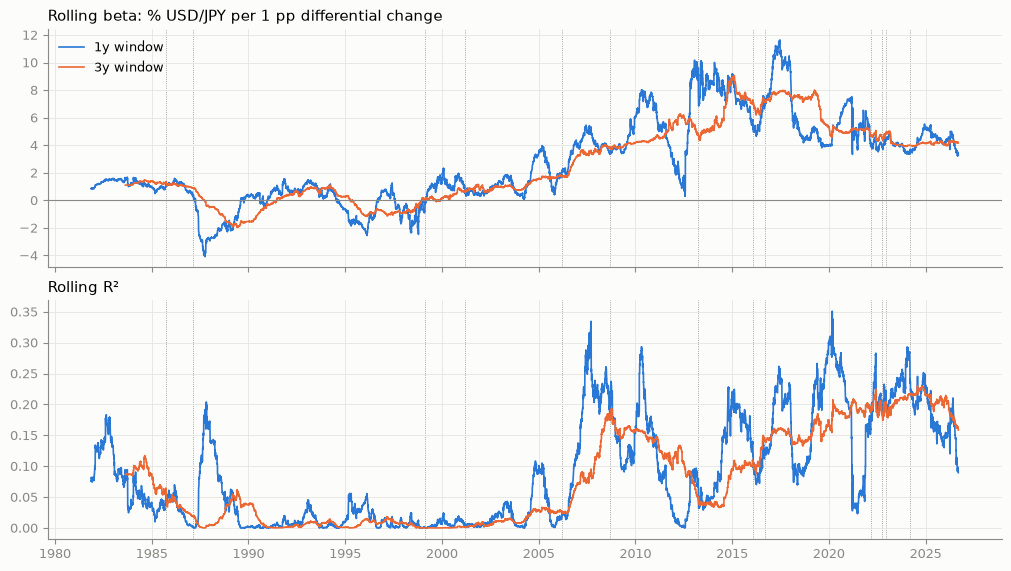

In [8]:
fig = m.plot_rolling_beta(specs["primary"])
ex.save(fig, "h1a_rolling_beta")

## 9. Two-leg US/Japan decomposition — DESCRIPTIVE

§6.3: Δs = α + β_US·Δus + β_JP·Δjgb + ε by era, with HAC Wald tests of β_US = −β_JP
(equivalently β_US + β_JP = 0). Where a leg is constant in an era its slope is not
identified and no test is reported. A non-rejection with a wide interval reflects
imprecision (the JGB leg was nearly pinned in 1999–2022), not evidence that the legs offset.

In [9]:
rows = {}
for era, t in analysis.legs.items():
    rows[era] = {"identified": t.identified}
    if t.identified and t.total is not None and t.wald is not None:
        rows[era] |= {
            "beta_us": analysis.two_leg.params[f"beta_us:{era}"],
            "beta_jp": analysis.two_leg.params[f"beta_jp:{era}"],
            "beta_us + beta_jp": t.total.estimate,
            "lower": t.total.lower,
            "upper": t.total.upper,
            "wald": t.wald.stat,
            "p": t.wald.p,
        }
display(pd.DataFrame(rows).T)
print("Leg spread (diagnostic):")
display(analysis.leg_spread)

,identified,beta_us,beta_jp,beta_us + beta_jp,lower,upper,wald,p
1981–1989,True,0.921866,2.051083,2.972949,1.859553,4.086345,27.388734,0.0
1990–1998,True,0.14713,0.86501,1.01214,-0.187008,2.211288,2.736728,0.098065
1999–2012,True,2.703787,-2.058204,0.645583,-1.867192,3.158359,0.253567,0.614574
2013–2021,True,6.915929,0.752083,7.668012,2.44868,12.887344,8.291477,0.003983
2022–,True,4.210484,-0.189903,4.020581,0.838661,7.2025,6.133318,0.013266


Leg spread (diagnostic):


,n,sd_dus,sd_djgb
1981–1989,2038,0.119588,0.041161
1990–1998,2035,0.059858,0.038848
1999–2012,3154,0.058308,0.014341
2013–2021,2007,0.030932,0.009171
2022–,1045,0.072063,0.016250


## 10. Robustness R1–R3 — ROBUSTNESS

§9.1: each variant re-runs the §5.1 rule with one change. R1: lagged US leg. R2: monthly
month-end changes (low power). R3: 10Y differential. The label is "robust" only if all
three share the primary category; robustness never changes the primary outcome.

In [10]:
display(h1a.results_table(analysis.results))
print(f"Primary outcome: {analysis.primary.outcome}   Robustness label: {analysis.robustness}")

,status,n_ref,n_new,hac_lag,beta_ref,beta_new,delta,L (97.5% lower),U (97.5% upper),p_S,p_R,gate,outcome
primary,confirmatory,2007,1045,11,6.444615,4.05464,-0.24177,-1.146316,0.662777,0.300186,0.699814,True,inconclusive
R1,robustness,2007,1045,11,1.431943,0.749344,-0.205284,-1.230192,0.819625,0.347318,0.652682,True,inconclusive
R2,robustness,108,56,5,4.384214,7.450909,4.5281,1.574212,7.481989,0.99867,0.00133,True,ruled out
R3,robustness,2007,1045,10,4.991424,4.199257,0.871641,0.009861,1.733422,0.976282,0.023718,True,ruled out


Primary outcome: inconclusive   Robustness label: sensitive to R2 (ruled out), R3 (ruled out)


## 11. Statistical interpretation and limitations

Written after the single execution, from the outputs above. Nothing here changes a
specification or the outcome; it follows the association language of ADR 0006 §3.

### Confirmatory result (sections 4–6)

**H1a outcome: inconclusive.** The gate passes decisively (L_ref = 5.46 > 0). Neither
directional test rejects: S has U = 0.663, which is not < 0 (p_S = 0.300), and R has
L = −1.146, which is not > 0 (p_R = 0.700). Under the frozen rule the data cannot tell
whether the association declined by at least the preselected one-third.

- **Estimated decline.** β fell from 6.44 % per pp (95% CI 5.46–7.43) in 2013–2021 to
  4.05 (3.43–4.67) since 2022. δ = β_new − (2/3)β_ref = −0.24, 95% interval
  [−1.15, 0.66], z = −0.52.
- **Size, and why the threshold is not resolved.** The relative change is −37.1%, with
  Fieller 95% set [−49.4%, −21.7%]. The set is bounded because β_ref is far from zero.
  It contains the −33.3% threshold, so the data are compatible both with declines
  smaller than a third (down to about a fifth) and with larger ones (up to about a
  half). That is exactly what "inconclusive" means. It is not evidence of no change.
- **A decline of some size.** The absolute change −2.39 % per pp has a 95% interval of
  [−3.56, −1.22], which excludes zero. This is reported, not a confirmatory test: H1a
  asks about a *material* decline, and that remains unresolved.
- **Explanatory share rose.** R² is 0.133 in 2013–2021 and 0.191 since 2022. The
  differential has been far more volatile since 2022, which outweighs the smaller slope:
  per point the association is weaker, but the differential accounts for more of daily
  USD/JPY variation, not less. In R² terms there is no sign of decoupling.
- **Expected precision.** The point ratio, 0.629, is almost exactly the ≈ 0.63 implied by
  exploratory statistics and disclosed before the freeze (ADR 0006 §1.1). The formal test
  added valid uncertainty and a pre-committed classification, not a surprise.

### Secondary (section 7)

The era-equality Wald test rejects one β for all five eras (χ²(4) = 239.4, p ≈ 1e−50).
This mainly reflects the near-zero slopes of 1981–1998 against the much larger slopes
since 2013. It says the relationship has not been stable over 45 years. It says nothing
specific about 2013–2021 versus 2022–, and it does not decide H1a.

### Descriptive (sections 8–9)

- **Rolling β.** The slope rises from about zero (late 1980s to early 2000s) to its highest
  values around 2013–2019, then falls to about 4–5. By eye, the 3-year window is already
  near its post-2022 level around 2020–2021, before the candidate boundary. This is a
  visual reading with no inference. It is consistent with assumption A6: if the change
  predates 2022, the reference era mixes regimes and the contrast is biased toward no
  change. Break-date inference is deferred to the structural-break ADR.
- **Two legs.** In both compared eras the association runs almost entirely through the
  US 2Y leg: β_US = 6.92 and 4.21, against β_JP = 0.75 and −0.19. The "equal and
  opposite" restriction is rejected (p = 0.004 and 0.013), so the 2Y differential does not
  behave as one variable there. JGB-leg changes are small (sd 0.009 and 0.016 pp), so β_JP
  is imprecise and the intervals are wide. Display note: the table's p for 1981–1989
  shows as 0.0; the exact value from χ²(1) = 27.39 is about 1.7e−7.

### Robustness (section 10)

Label: **sensitive to R2 (ruled out), R3 (ruled out)**. The primary outcome is unchanged.

- **R1 (lagged US leg): inconclusive.** Its slopes are small (1.43 and 0.75) because this
  variant mostly measures a lead–lag relationship (§4.5).
- **R2 (monthly): material decline ruled out** (L = 1.57, p_R = 0.001). The monthly point
  estimate is *higher* since 2022 (7.45 against 4.38) but rests on only 56 new-era
  months. Whether it actually rose was not tested.
- **R3 (10Y): material decline ruled out, narrowly** (L = 0.010, p_R = 0.024, just inside
  0.025).
- **Reading.** The daily-2Y estimate of a weaker per-point association does not carry over
  to the monthly horizon or to the 10Y differential. The protocol cannot separate horizon
  effects, timing artefacts (A5) and maturity differences.

### What these results do not support

- A finding that the yen "decoupled" from the differential: the confirmatory test is
  inconclusive, and the robustness checks point the other way.
- Any causal statement (common shocks, reverse causality) or any forecasting claim.
- Anything about long-run (levels) decoupling, which is H1b and not yet specified or
  tested.

### Limitations

- **Same-day timing (A5).** β is a projection coefficient over misaligned windows (US
  close about 15:30, JGB about 01:00, FX fix at noon New York). The distortion may differ
  between eras, and the monthly disagreement is consistent with that.
- **Changing yield volatility.** Differential volatility more than doubled after 2021,
  so slope and R² move in opposite directions. β_ref comes from the quietest era, which
  is why its interval is wider.
- **The 2022-01 boundary** is a candidate. The rolling β suggests the change may predate
  it (A6).
- **Changing role of Japanese yields.** The JGB leg was nearly pinned until 2022 and
  moves more since 2024, but its coefficient stays small and imprecise. The 2Y
  differential is mainly a US-yield measure in both compared eras.
- **Pre-specified, not blind** (§1.1). The normal approximation may be slightly liberal
  (A7). Large genuine market days are kept, with no trimming, and no influence
  diagnostics are part of the protocol.


## 12. Reproducibility information

**Execution record (Stage 3B):** a single `make h1a` run on 2026-10-21. Every code cell
ran once, top to bottom (execution counts 1–11), with no errors or warnings.

- Code: commit `dd8d04fe50f79fb0b24d3299515052ddfca26889`.
- Data: the frozen vintage downloaded 2026-09-15, with all 8 ADR 0006 §9.2 checksums
  verified in section 2.
- Figure: `reports/figures/h1a_rolling_beta.png` (SHA-256 `14f39174…bcf5e`).

The cell below printed `working_tree modified` during that run. The only change at the
time was the figure that section 8 had just written (an untracked file); no source file
differed from `dd8d04f`. The provenance report was corrected afterwards (Stage 3C) to
check tracked source files only (`source_tree`), and the stored output is left as
produced.

In [11]:
for k, v in h1a.provenance().items():
    print(f"{k:14s} {v}")
print("data checksums: verified against ADR 0006 §9.2 in section 2")
print("randomness: none (no bootstrap in H1a)")

git_commit     dd8d04fe50f79fb0b24d3299515052ddfca26889
working_tree   modified
python         3.12.8
pandas         3.0.5
numpy          2.5.3
statsmodels    0.15.0
matplotlib     3.11.1
data checksums: verified against ADR 0006 §9.2 in section 2
randomness: none (no bootstrap in H1a)
